Data 620 - Project 2

Yana Rabkova

**Introduction**

Video presentation link: https://youtu.be/AFbS9qlFXPQ

The dataset link: https://snap.stanford.edu/biodata/datasets/10018/10018-ChSe-Decagon.html 


In this project, I explore drug–side effect relationships using bipartite network analysis. The goal is to understand how drugs are connected through their reported side effects and identify groups of drugs with similar side-effect profiles. I first construct a bipartite network and then project it onto a drug–drug network to examine shared side effects and identify meaningful patterns.


In [2]:
import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite


# Load drug-side effect associations
df = pd.read_csv(
    "/Users/yanarabkova/Desktop/Yana/CUNY masters/DATA 620 - Web Analytics/Week 6 - Project 2/ChSe-Decagon_monopharmacy.csv.gz",
    compression="gzip"
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

# stitch - unique drug identifier, other variables related to side effect (individual side effect, side effect name)

Dataset shape: (174977, 3)
Columns: ['# STITCH', 'Individual Side Effect', 'Side Effect Name']
       # STITCH Individual Side Effect                Side Effect Name
0  CID003062316               C1096328     central nervous system mass
1  CID003062316               C0162830       Photosensitivity reaction
2  CID003062316               C1611725    leukaemic infiltration brain
3  CID003062316               C0541767  platelet adhesiveness abnormal
4  CID003062316               C0242973         Ventricular dysfunction


In [3]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Count unique drugs and side effects
print("\nUnique drugs:", df["# STITCH"].nunique())
print("Unique side effects:", df["Individual Side Effect"].nunique())

# Check duplicate drug-side effect relationships
print("\nDuplicate relationships:",
      df.duplicated(subset=["# STITCH", "Individual Side Effect"]).sum())

# Remove duplicate relationships
df_clean = df.drop_duplicates(
    subset=["# STITCH", "Individual Side Effect"]
).copy()

print("\nCleaned dataset shape:", df_clean.shape)

Missing values:
# STITCH                  0
Individual Side Effect    0
Side Effect Name          0
dtype: int64

Unique drugs: 639
Unique side effects: 10184

Duplicate relationships: 0

Cleaned dataset shape: (174977, 3)


**Dataset Description**

This project uses the SIDER dataset, which contains information about drugs and their reported side effects. The dataset is used to construct a bipartite network, where drugs and side effects represent two different types of nodes, and edges represent reported associations between them.

The resulting network contains 639 drugs, 10,184 unique side effects, and 174,977 drug–side effect associations.

In [4]:
import networkx as nx
from networkx.algorithms import bipartite

B = nx.Graph()

# Add drug nodes
drugs = df_clean["# STITCH"].unique()
B.add_nodes_from(drugs, bipartite=0, node_type="drug")

# Add side-effect nodes
side_effects = df_clean["Individual Side Effect"].unique()
B.add_nodes_from(side_effects, bipartite=1, node_type="side_effect")

# Add edges between drugs and side effects
B.add_edges_from(
    df_clean[["# STITCH", "Individual Side Effect"]].itertuples(
        index=False, name=None
    )
)

print("Total nodes:", B.number_of_nodes())
print("Total edges:", B.number_of_edges())
print("Is bipartite:", nx.is_bipartite(B))
print("Connected components:", nx.number_connected_components(B))

Total nodes: 10823
Total edges: 174977
Is bipartite: True
Connected components: 1


I constructed a bipartite network with two types of nodes: drugs and side effects. Each edge represents an association between a drug and a reported side effect.

This allows us to examine how drugs and side effects are connected and identify patterns in their relationships.

In [5]:
# Calculate degree for each drug
drug_degrees = pd.DataFrame({
    "Drug": drugs,
    "Degree": [B.degree(drug) for drug in drugs]
}).sort_values("Degree", ascending=False)

# Calculate degree for each side effect
side_effect_degrees = pd.DataFrame({
    "Side Effect ID": side_effects,
    "Degree": [B.degree(effect) for effect in side_effects]
}).sort_values("Degree", ascending=False)

# Add descriptive side effect names
effect_names = df_clean[
    ["Individual Side Effect", "Side Effect Name"]
].drop_duplicates(subset=["Individual Side Effect"])

side_effect_degrees = side_effect_degrees.merge(
    effect_names,
    left_on="Side Effect ID",
    right_on="Individual Side Effect",
    how="left"
)

print("Top 10 drugs:")
print(drug_degrees.head(10))

print("\nTop 10 side effects:")
print(side_effect_degrees[
    ["Side Effect Name", "Degree"]
].head(10))

Top 10 drugs:
             Drug  Degree
119  CID000068740    1550
403  CID000004674    1515
210  CID000005538    1229
211  CID000000444    1186
209  CID000005064    1045
492  CID000005090     979
635  CID000005376     947
137  CID000093860     927
600  CID000003902     896
508  CID000002818     871

Top 10 side effects:
                        Side Effect Name  Degree
0  general physical health deterioration     301
1                          hypoaesthesia     279
2                  mental status changes     278
3                       tooth extraction     276
4                     emotional distress     275
5     alanine aminotransferase increased     273
6                   condition aggravated     270
7                            pollakiuria     267
8               staphylococcal infection     266
9             blood creatinine increased     263


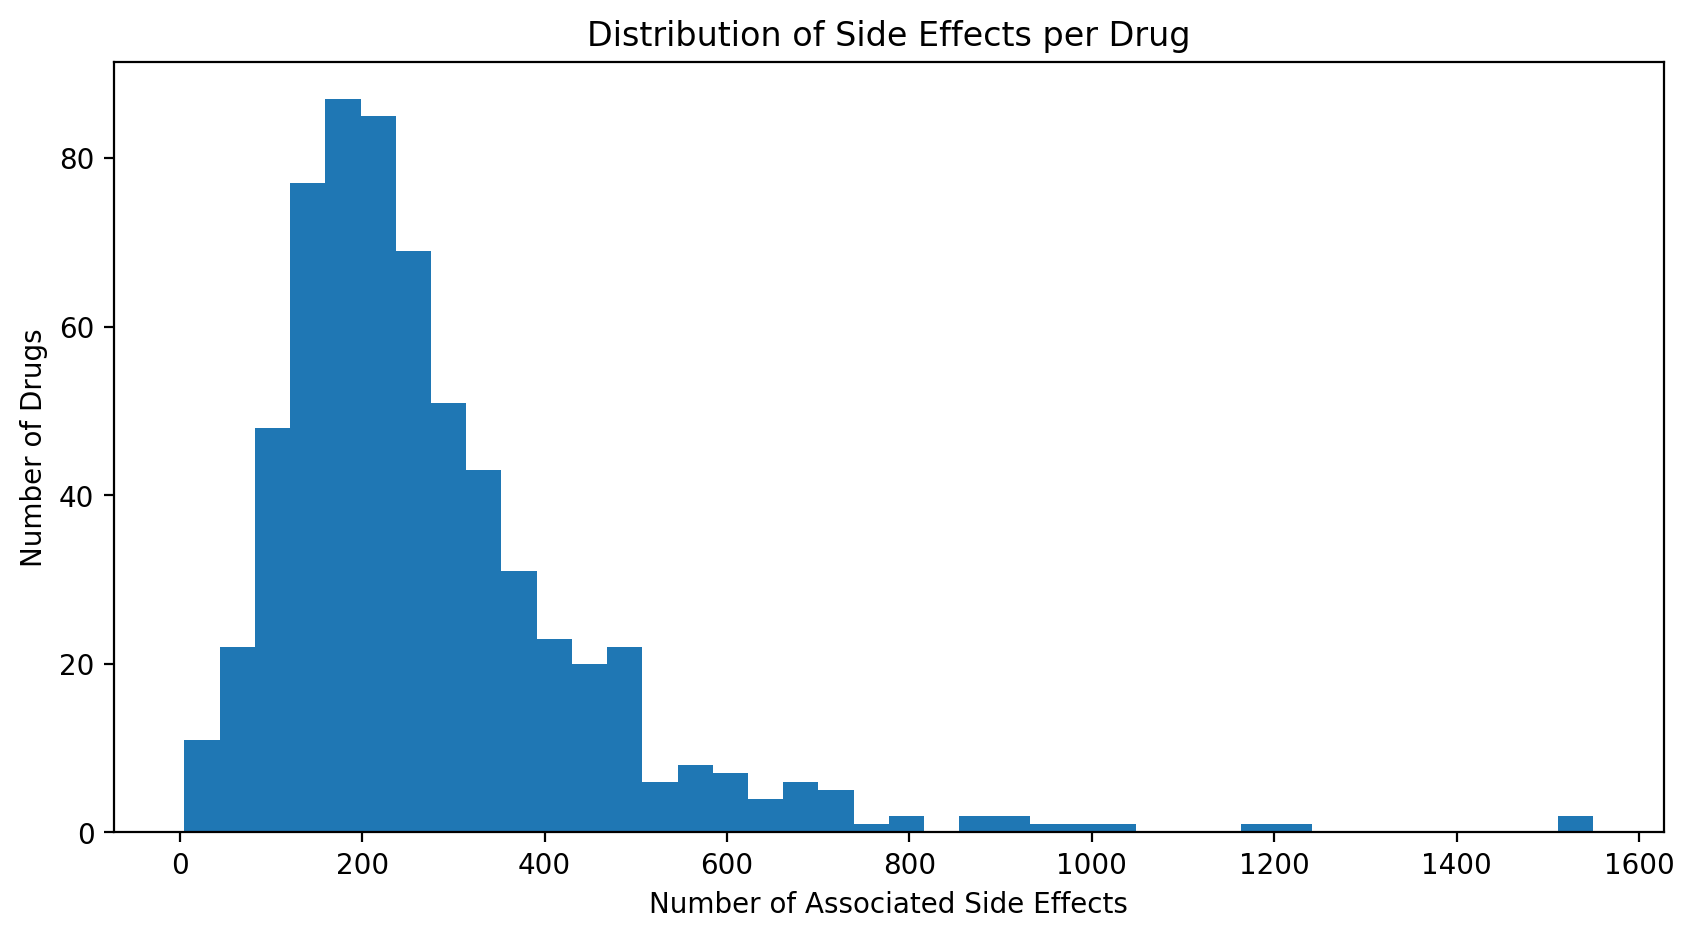

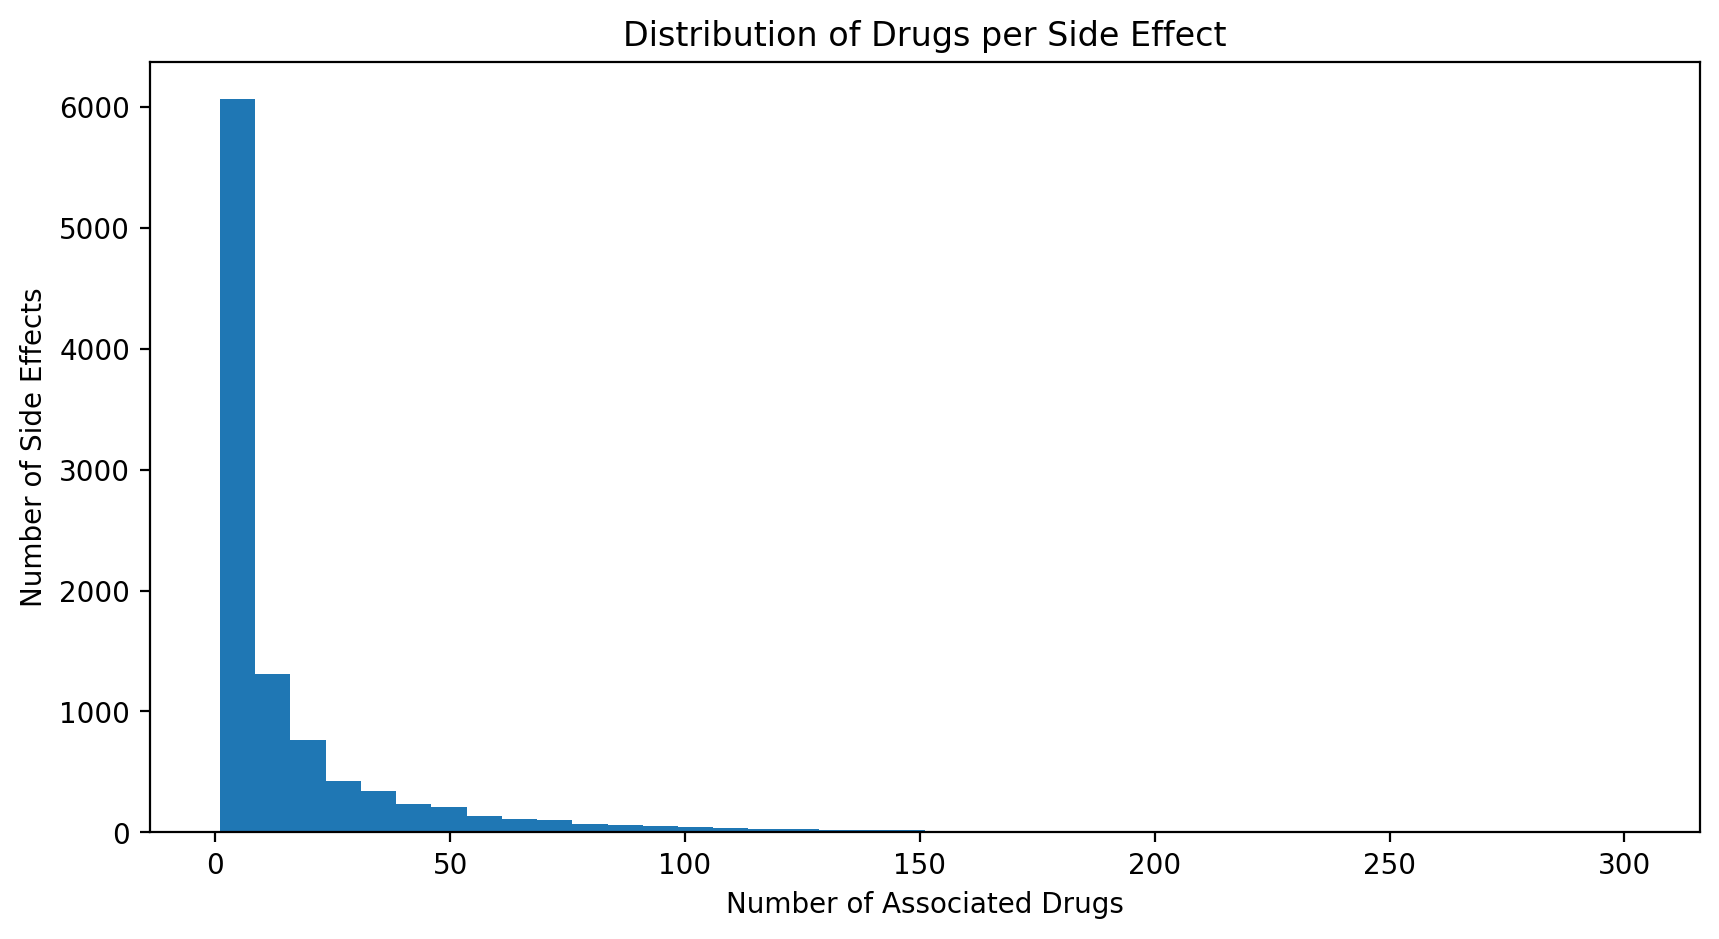

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(drug_degrees["Degree"], bins=40)
plt.title("Distribution of Side Effects per Drug")
plt.xlabel("Number of Associated Side Effects")
plt.ylabel("Number of Drugs")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(side_effect_degrees["Degree"], bins=40)
plt.title("Distribution of Drugs per Side Effect")
plt.xlabel("Number of Associated Drugs")
plt.ylabel("Number of Side Effects")
plt.show()

In [7]:

from networkx.algorithms import bipartite

# Create weighted drug projection
G_drugs = bipartite.weighted_projected_graph(
    B, drugs
)

print("Projected drug network:")
print("Nodes:", G_drugs.number_of_nodes())
print("Edges:", G_drugs.number_of_edges())

# Examine distribution of edge weights
weights = pd.Series([
    data["weight"]
    for _, _, data in G_drugs.edges(data=True)
])

print("\nShared side-effect counts:")
print(weights.describe())

print("\nWeight percentiles:")
print(weights.quantile([0.50, 0.75, 0.90, 0.95, 0.99]))


Projected drug network:
Nodes: 639
Edges: 202120

Shared side-effect counts:
count    202120.000000
mean         29.886429
std          26.606471
min           1.000000
25%          13.000000
50%          23.000000
75%          38.000000
max        1066.000000
dtype: float64

Weight percentiles:
0.50     23.0
0.75     38.0
0.90     59.0
0.95     78.0
0.99    128.0
dtype: float64


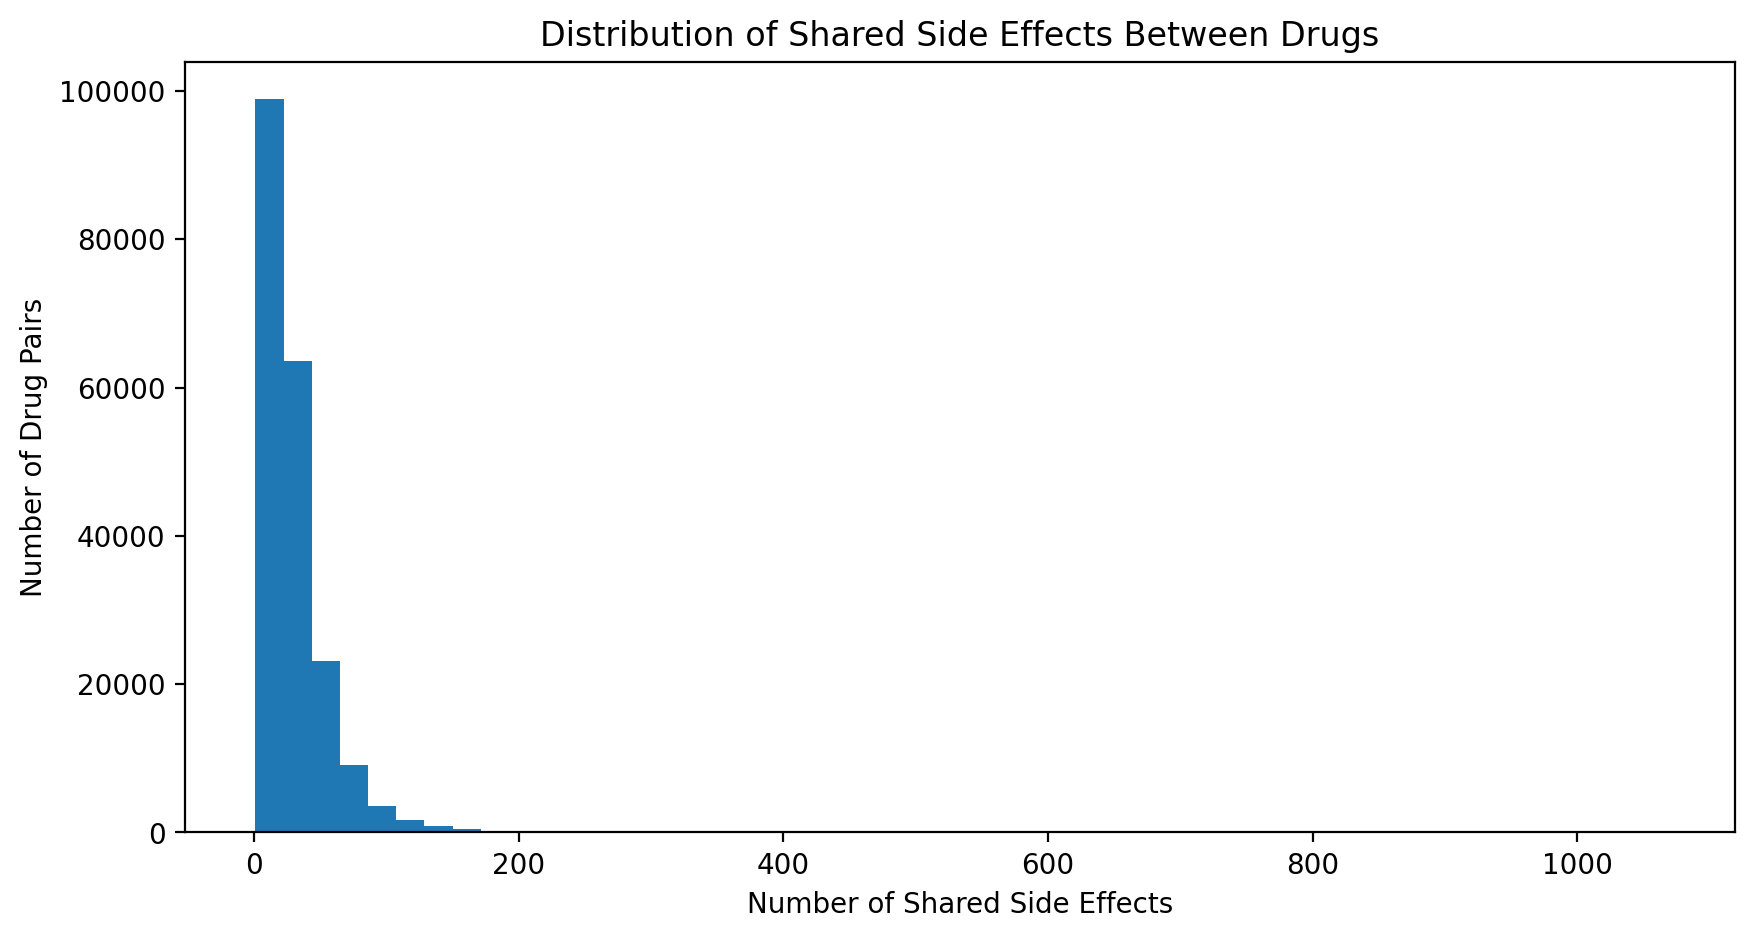

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(weights, bins=50)

plt.title("Distribution of Shared Side Effects Between Drugs")
plt.xlabel("Number of Shared Side Effects")
plt.ylabel("Number of Drug Pairs")

plt.show()


In [ ]:
from networkx.classes.graph import Graph
from typing import Any

thresholds: dict[Any, Any] = weights.quantile(
    [0.75, 0.90, 0.95, 0.99]
).to_dict()

results: list[Any] = []

for percentile, threshold in thresholds.items():

    G_filtered: Graph[Any, dict[str, Any], Any] = nx.Graph(
        (u, v, d)
        for u, v, d in G_drugs.edges(data=True)
        if d["weight"] >= threshold
    )

    components = list(nx.connected_components(G_filtered))

    results.append({
        "Percentile": percentile,
        "Threshold": threshold,
        "Nodes": G_filtered.number_of_nodes(),
        "Edges": G_filtered.number_of_edges(),
        "Components": len(components),
        "Largest Component": max(
            (len(c) for c in components),
            default=0
        )
    })

reduction_results = pd.DataFrame(results)
print(reduction_results)


   Percentile  Threshold  Nodes  Edges  Components  Largest Component
0        0.75       38.0    602  51790           1                602
1        0.90       59.0    532  20994           1                532
2        0.95       78.0    439  10137           1                439
3        0.99      128.0    229   2080           1                229


In [10]:

# Explore stricter weight thresholds
thresholds = [128, 150, 175, 200, 250, 300, 400, 500]

results = []

for threshold in thresholds:
    G_filtered = nx.Graph(
        (u, v, d)
        for u, v, d in G_drugs.edges(data=True)
        if d["weight"] >= threshold
    )

    components = sorted(
        nx.connected_components(G_filtered),
        key=len,
        reverse=True
    )

    results.append({
        "Threshold": threshold,
        "Nodes": G_filtered.number_of_nodes(),
        "Edges": G_filtered.number_of_edges(),
        "Components": len(components),
        "Largest Component": len(components[0]) if components else 0,
        "Second Largest": len(components[1]) if len(components) > 1 else 0
    })

pd.DataFrame(results)


,Threshold,Nodes,Edges,Components,Largest Component,Second Largest
0,128,229,2080,1,229,0
1,150,176,1169,3,169,5
2,175,114,657,1,114,0
3,200,88,395,1,88,0
4,250,52,163,1,52,0
5,300,33,80,2,31,2
6,400,13,22,1,13,0
7,500,6,9,1,6,0


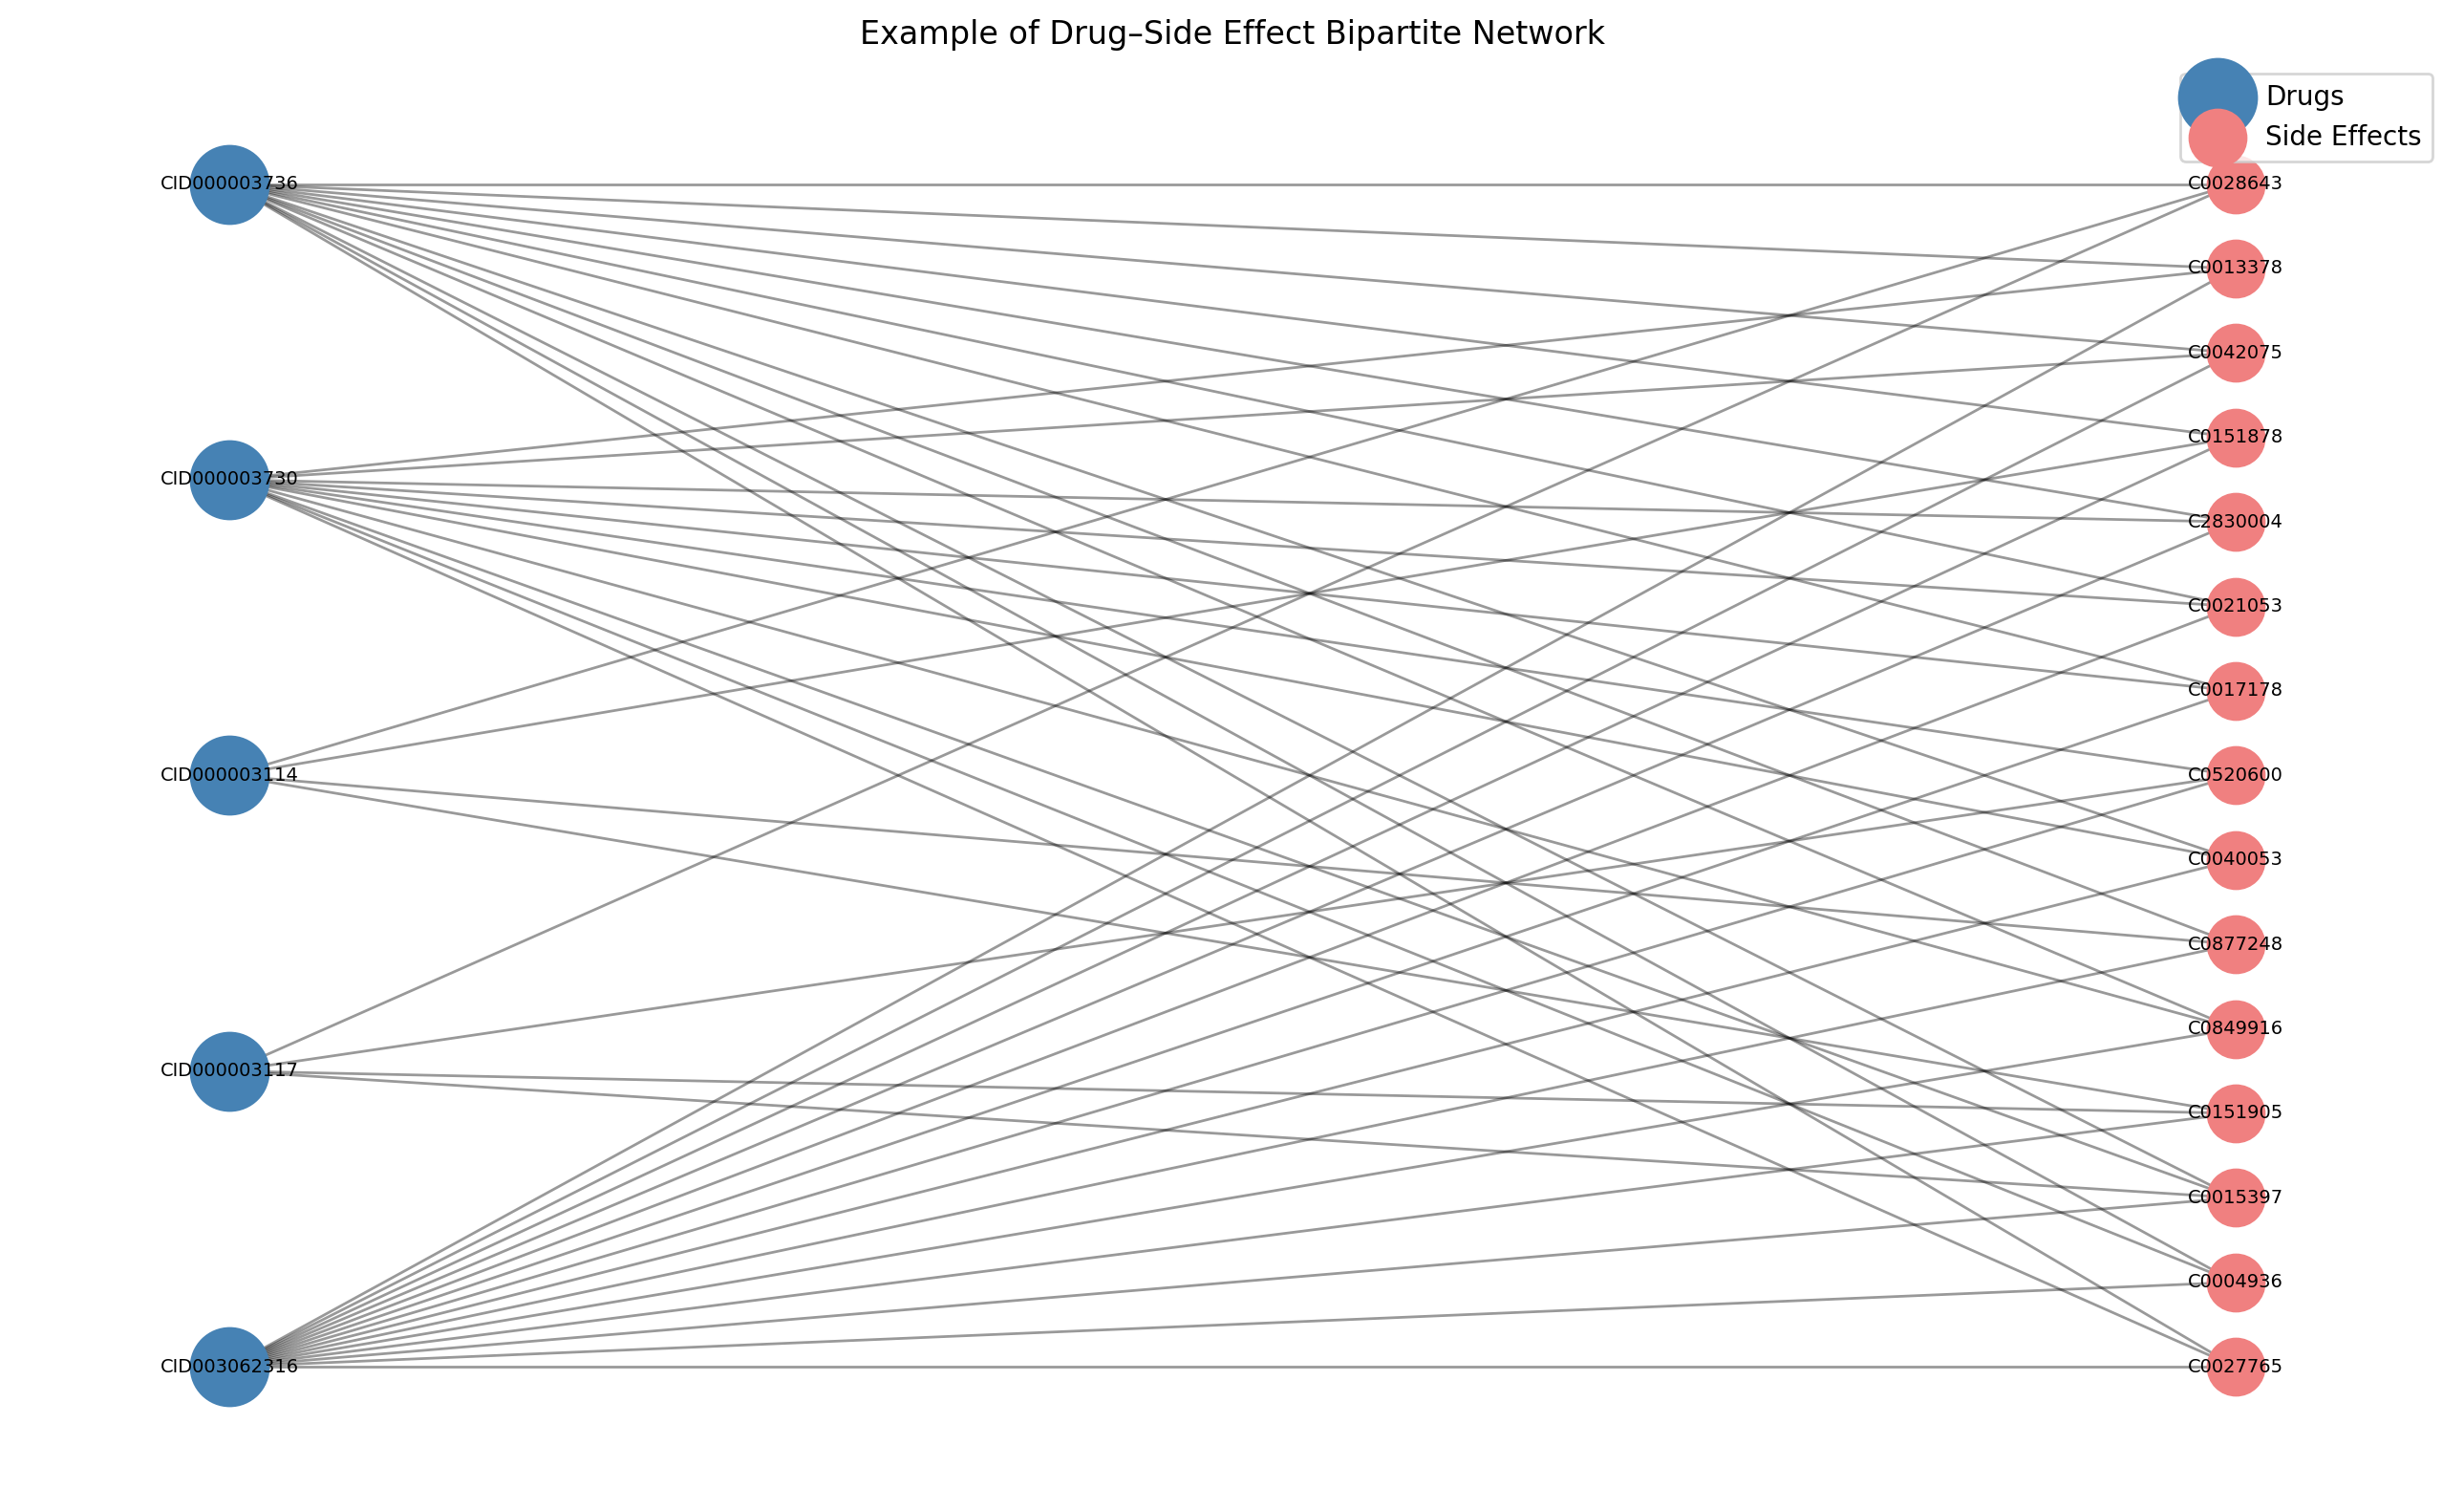

In [11]:

import matplotlib.pyplot as plt
import networkx as nx

# Select 5 drugs for a readable example
sample_drugs = list(drugs[:5])

# Find side effects shared by at least 2 selected drugs
effect_counts = {}

for drug in sample_drugs:
    for effect in B.neighbors(drug):
        effect_counts[effect] = effect_counts.get(effect, 0) + 1

shared_effects = [
    effect for effect, count in effect_counts.items()
    if count >= 2
]

# Limit to 15 side effects
sample_effects = sorted(
    shared_effects,
    key=lambda x: effect_counts[x],
    reverse=True
)[:15]

# Create a smaller bipartite graph
selected_nodes = sample_drugs + sample_effects
B_sample = B.subgraph(selected_nodes).copy()

# Draw the network
pos = nx.bipartite_layout(B_sample, sample_drugs)

plt.figure(figsize=(13, 8))

nx.draw_networkx_nodes(
    B_sample, pos,
    nodelist=sample_drugs,
    node_color="steelblue",
    node_size=850,
    label="Drugs"
)

nx.draw_networkx_nodes(
    B_sample, pos,
    nodelist=sample_effects,
    node_color="lightcoral",
    node_size=450,
    label="Side Effects"
)

nx.draw_networkx_edges(
    B_sample, pos,
    alpha=0.4
)

nx.draw_networkx_labels(
    B_sample, pos,
    font_size=7
)

plt.title("Example of Drug–Side Effect Bipartite Network")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()


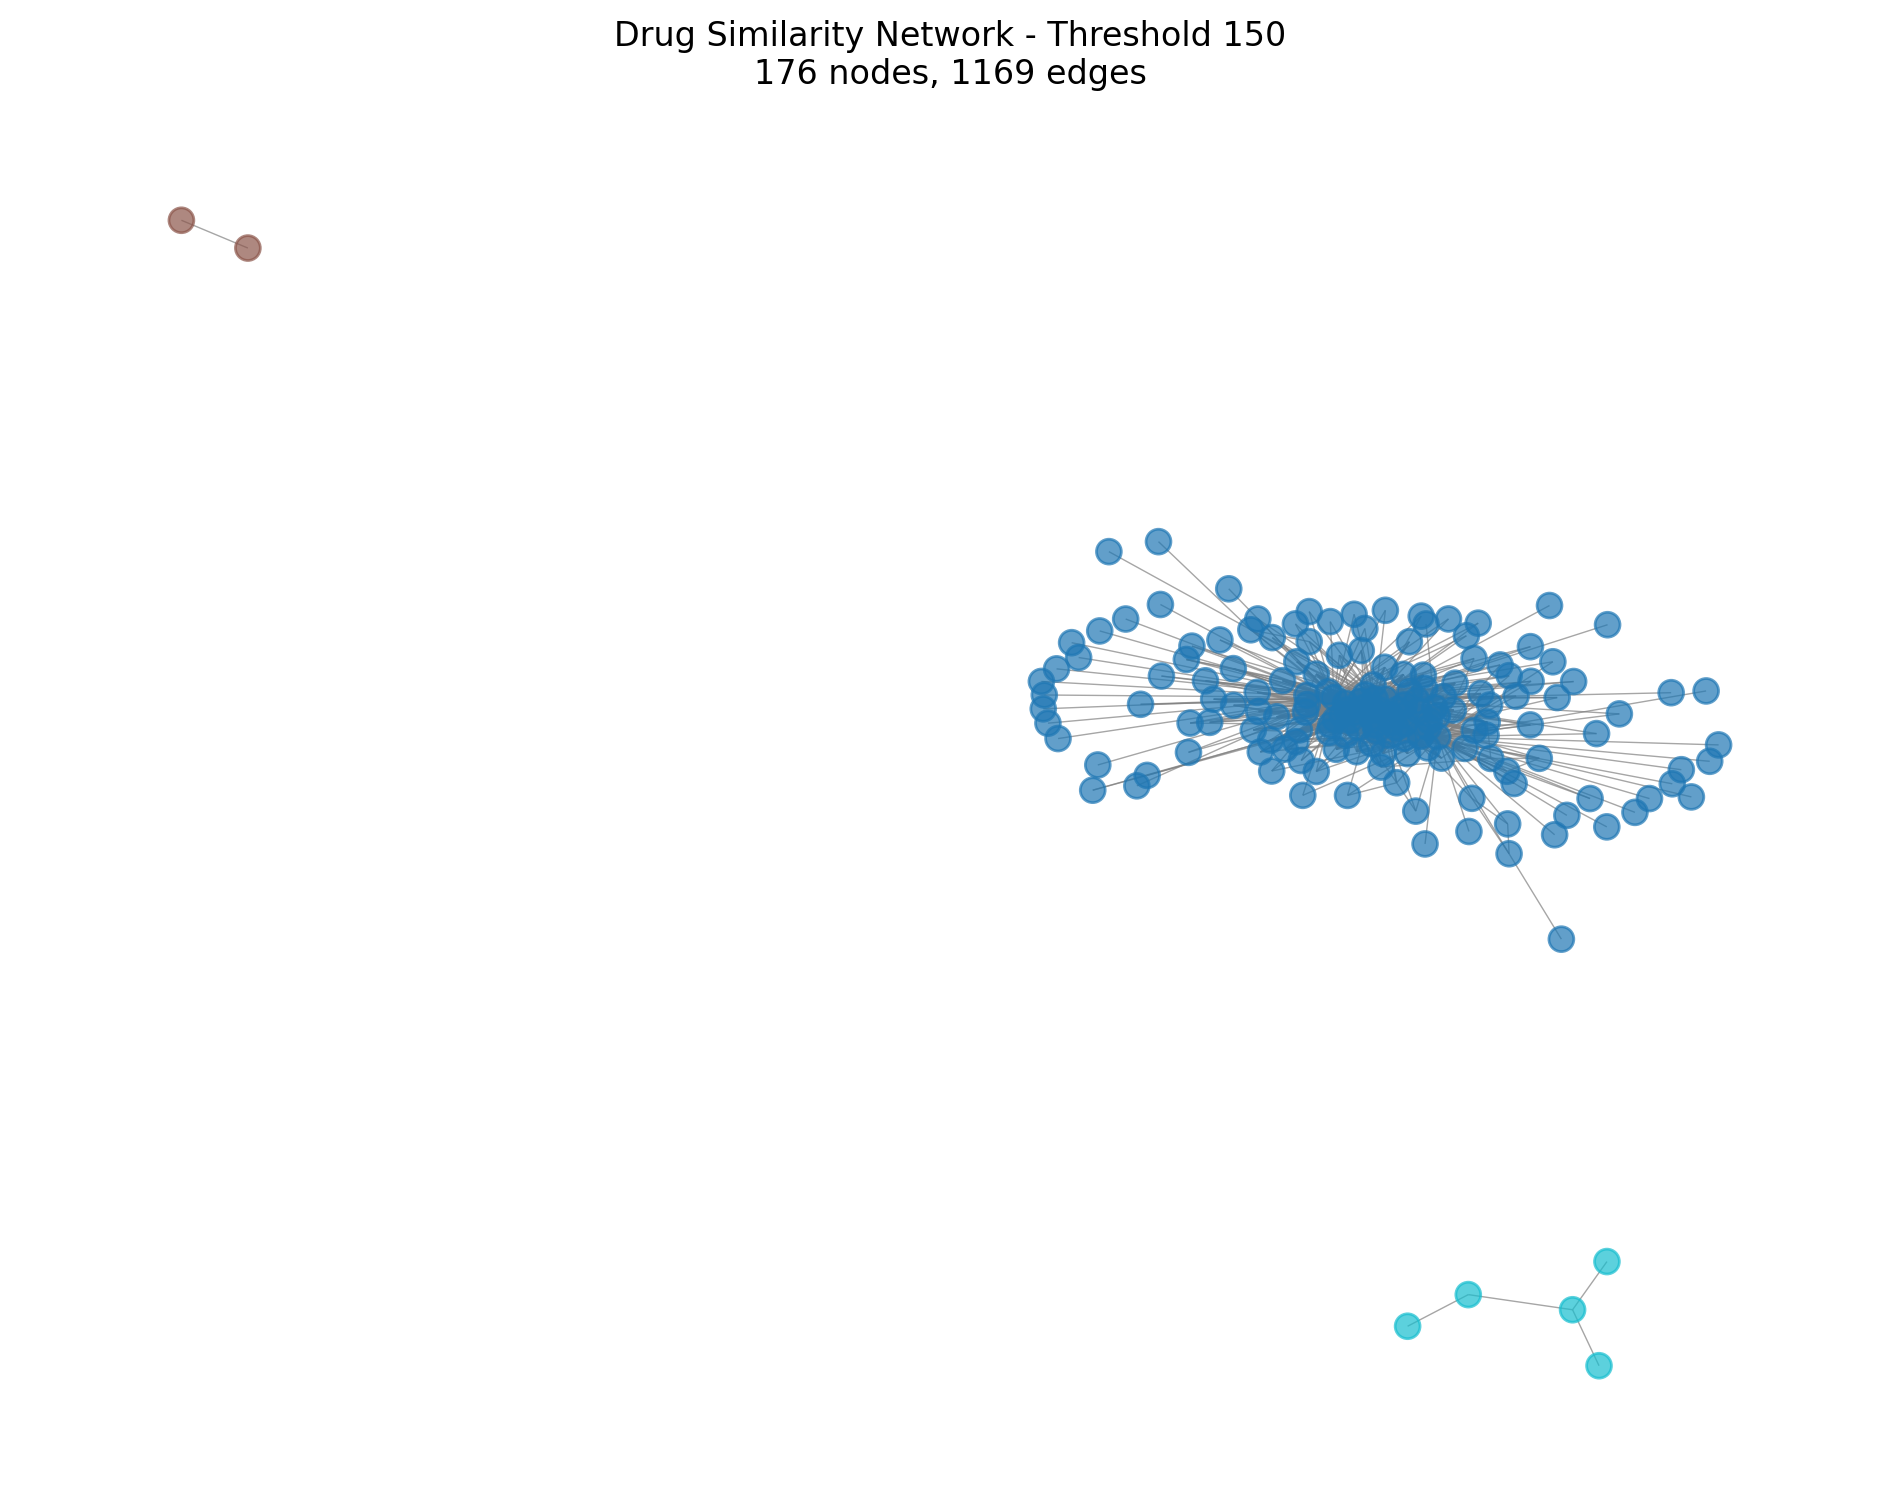

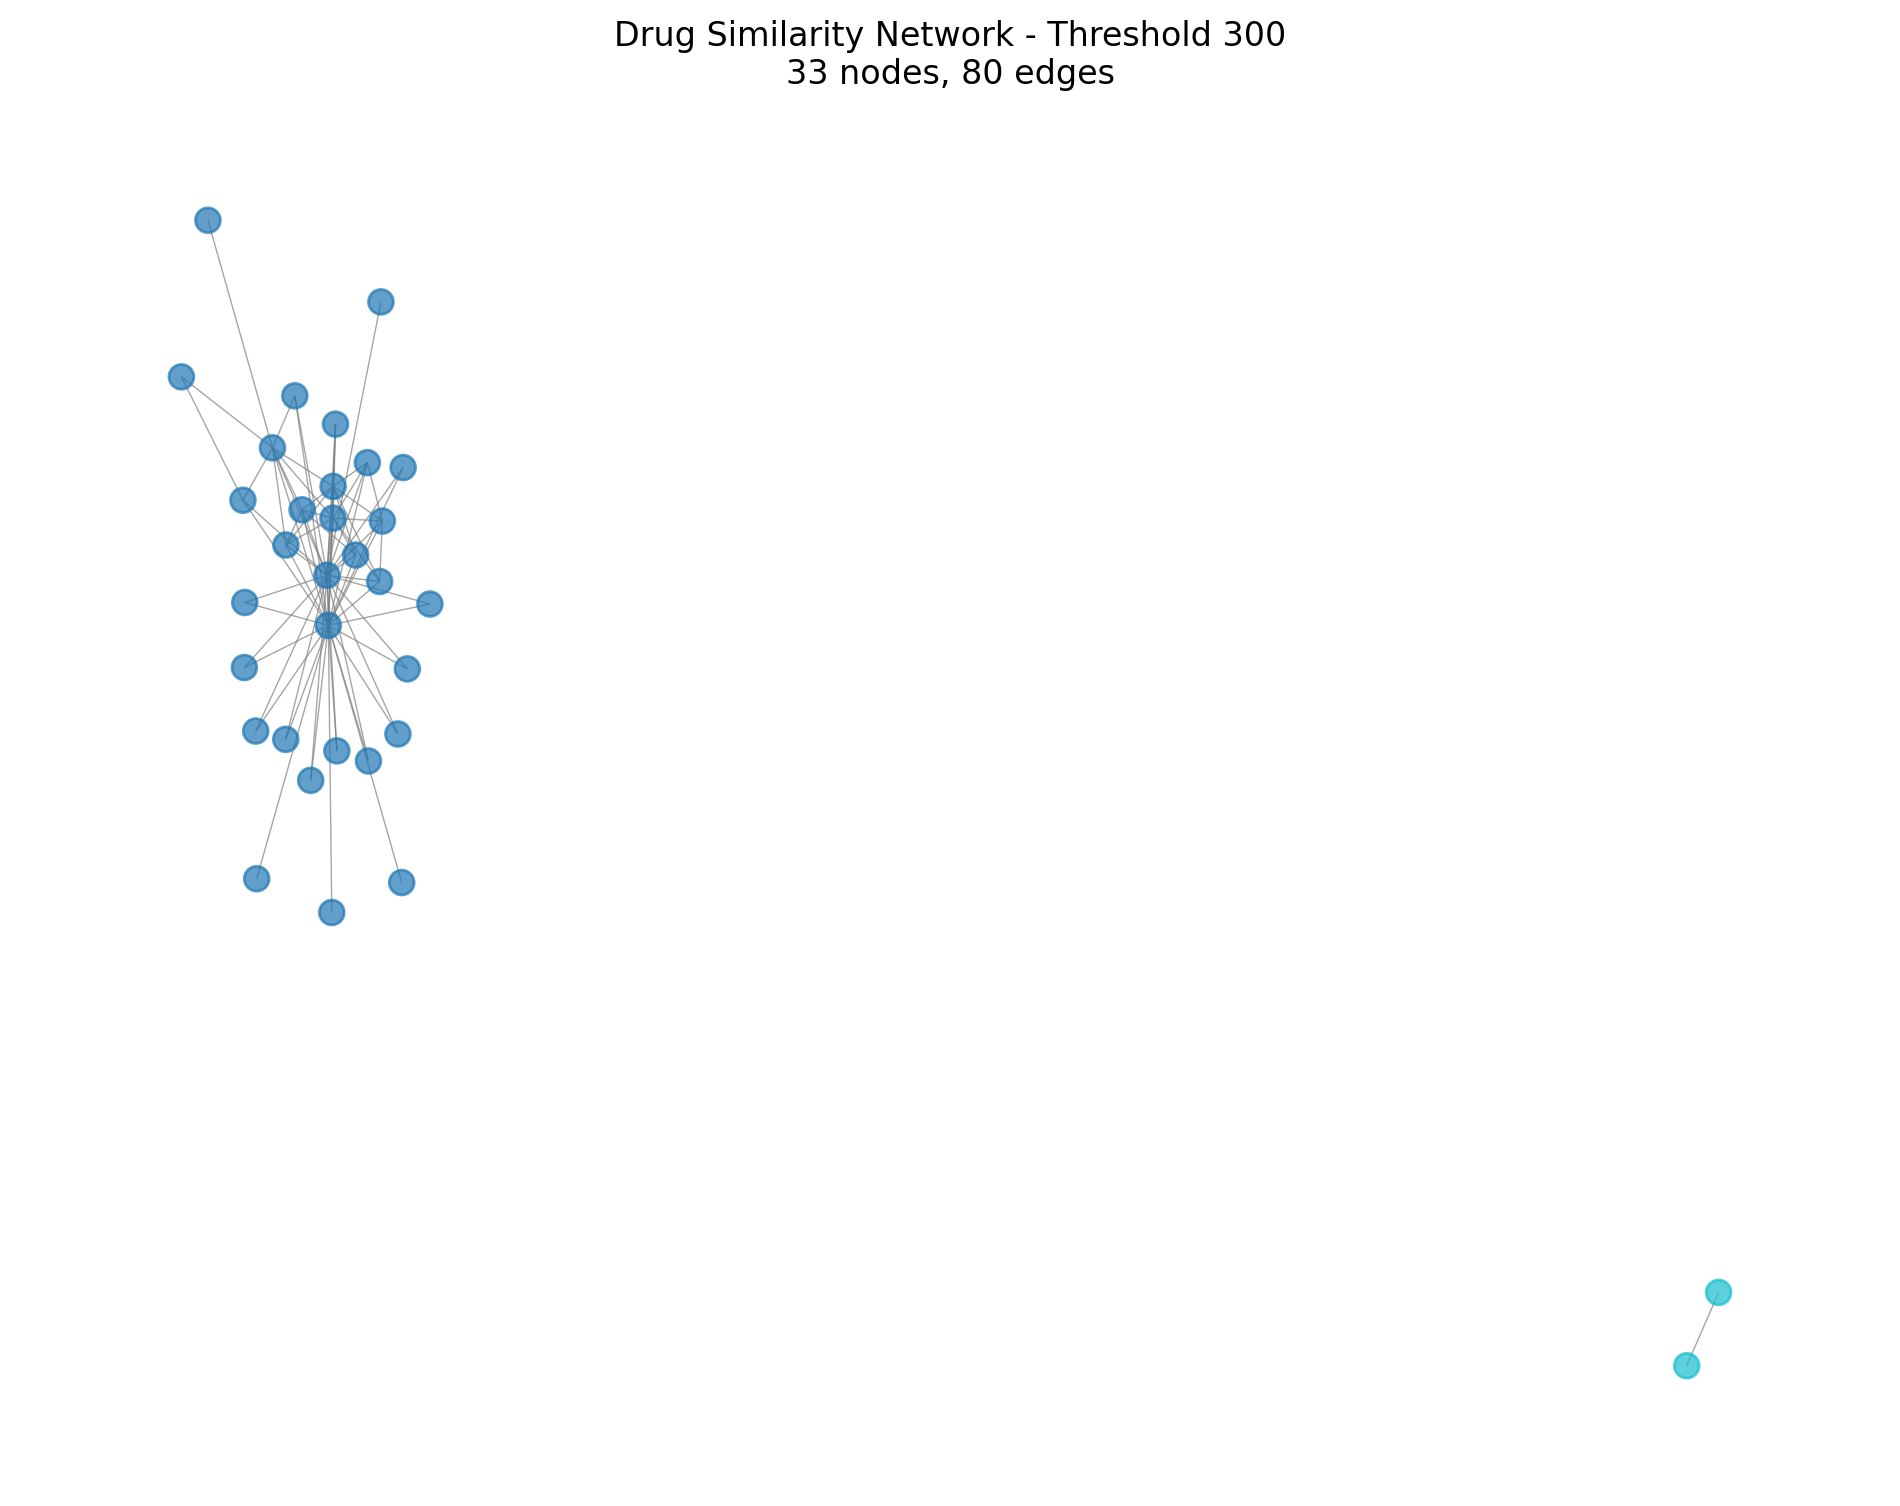

In [12]:

import matplotlib.pyplot as plt
import networkx as nx

def plot_island_network(G, threshold):

    G_filtered = nx.Graph(
        (u, v, d)
        for u, v, d in G.edges(data=True)
        if d["weight"] >= threshold
    )

    components = list(nx.connected_components(G_filtered))

    component_map = {}
    for i, component in enumerate(components):
        for node in component:
            component_map[node] = i

    node_colors = [
        component_map[node]
        for node in G_filtered.nodes()
    ]

    plt.figure(figsize=(12, 9))

    pos = nx.spring_layout(
        G_filtered,
        seed=42,
        k=0.5
    )

    nx.draw_networkx(
        G_filtered,
        pos,
        node_color=node_colors,
        cmap=plt.cm.tab10,
        node_size=80,
        edge_color="gray",
        alpha=0.7,
        with_labels=False,
        width=0.5
    )

    plt.title(
        f"Drug Similarity Network - Threshold {threshold}\n"
        f"{G_filtered.number_of_nodes()} nodes, "
        f"{G_filtered.number_of_edges()} edges"
    )

    plt.axis("off")
    plt.show()

plot_island_network(G_drugs, 150)
plot_island_network(G_drugs, 300)


Increasing the threshold to 300 shared side effects reduces the network to 33 drugs and 80 connections, forming two connected components. Most drugs remain in one large component, while two drugs form a separate pair. Compared with the threshold of 150, the network becomes considerably smaller and less dense, highlighting drug pairs with greater overlap in their reported side-effect profiles.


To better understand the smaller connected components, I examined the drugs within each group and identified side effects shared by all drugs in the component. This helps explore whether these isolated groups have distinctive side-effect profiles.

In [13]:

# Examine small connected components
threshold = 150

G_filtered = nx.Graph(
    (u, v, d)
    for u, v, d in G_drugs.edges(data=True)
    if d["weight"] >= threshold
)

components = sorted(
    nx.connected_components(G_filtered),
    key=len,
    reverse=True
)

# Map side-effect IDs to readable names
effect_name_map = (
    df_clean
    .drop_duplicates("Individual Side Effect")
    .set_index("Individual Side Effect")["Side Effect Name"]
    .to_dict()
)

# Examine small components
for i, component in enumerate(components, 1):

    if len(component) <= 10:
        drug_list = sorted(component)

        print(f"\nComponent {i}: {len(drug_list)} drugs")
        print("Drug IDs:", drug_list)

        # Find side effects shared by all drugs
        common_effects = set(B.neighbors(drug_list[0]))

        for drug in drug_list[1:]:
            common_effects &= set(B.neighbors(drug))

        print("Common side effects:", len(common_effects))

        for effect in sorted(common_effects)[:15]:
            print("-", effect_name_map.get(effect, effect))



Component 2: 5 drugs
Drug IDs: ['CID000003043', 'CID000004451', 'CID000004463', 'CID000005726', 'CID005481350']
Common side effects: 19
- drug resistance
- foetal distress syndrome
- insulin resistance
- gamma-glutamyltransferase increased
- hyporeflexia
- alanine aminotransferase increased
- oesophageal varices haemorrhage
- foetal growth retardation
- progressive external ophthalmoplegia
- dyslipidaemia
- drug intolerance
- fat atrophy
- lipase
- portal hypertensive gastropathy
- blood amylase increased

Component 3: 2 drugs
Drug IDs: ['CID000060754', 'CID000444013']
Common side effects: 155
- body dysmorphic disorder
- bronchopneumonia
- calciphylaxis
- hypertrophic cardiomyopathy
- allergic granulomatous angiitis
- joint contracture
- stasis dermatitis
- dysgeusia
- localised oedema
- vascular graft occlusion
- hand deformity
- hyperparathyroidism secondary
- lichenification
- Nervous system disorder
- renal artery stenosis


At a threshold of 150, two smaller connected components were identified. Component 2 contained five drugs with 19 side effects common to all five, including several metabolic and liver-related terms. Component 3 contained two drugs sharing 155 reported side effects across multiple clinical categories.

These findings suggest that smaller components may represent groups of drugs with distinctive patterns of reported side-effect overlap. However, further investigation of drug identities and therapeutic classes is needed to determine whether these patterns have pharmacological significance.

In [14]:

# Calculate Jaccard similarity for connected drug pairs
drug_effects = {
    drug: set(B.neighbors(drug))
    for drug in drugs
}

for u, v, data in G_drugs.edges(data=True):
    shared = data["weight"]
    union = len(drug_effects[u]) + len(drug_effects[v]) - shared
    data["jaccard"] = shared / union if union else 0

# Show the most similar drug pairs
top_pairs = sorted(
    G_drugs.edges(data=True),
    key=lambda x: x[2]["jaccard"],
    reverse=True
)[:10]

pd.DataFrame([
    {
        "Drug 1": u,
        "Drug 2": v,
        "Shared Side Effects": d["weight"],
        "Jaccard Similarity": round(d["jaccard"], 3)
    }
    for u, v, d in top_pairs
])


,Drug 1,Drug 2,Shared Side Effects,Jaccard Similarity
0,CID000068740,CID000004674,1066,0.533
1,CID000004730,CID000002713,384,0.355
2,CID000003902,CID000005376,479,0.351
3,CID000104741,CID000003902,383,0.349
4,CID000104741,CID000060198,316,0.346
5,CID000060754,CID000444013,155,0.344
6,CID000104741,CID000005672,296,0.333
7,CID000104741,CID000005376,382,0.333
8,CID000002713,CID000004674,567,0.328
9,CID000068740,CID000003902,602,0.326


Jaccard Similarity Analysis

To account for differences in the total number of reported side effects across drugs, I calculated Jaccard similarity for each connected drug pair.

The highest similarity was observed between CID000068740 and CID000004674, which shared 1,066 side effects and had a Jaccard similarity of 0.533. This indicates that approximately 53% of their combined unique side-effect profiles overlap.

Interestingly, the two drugs forming a separate component in the threshold-150 network also showed relatively high Jaccard similarity (0.344), supporting the observation that they have overlapping side-effect profiles.

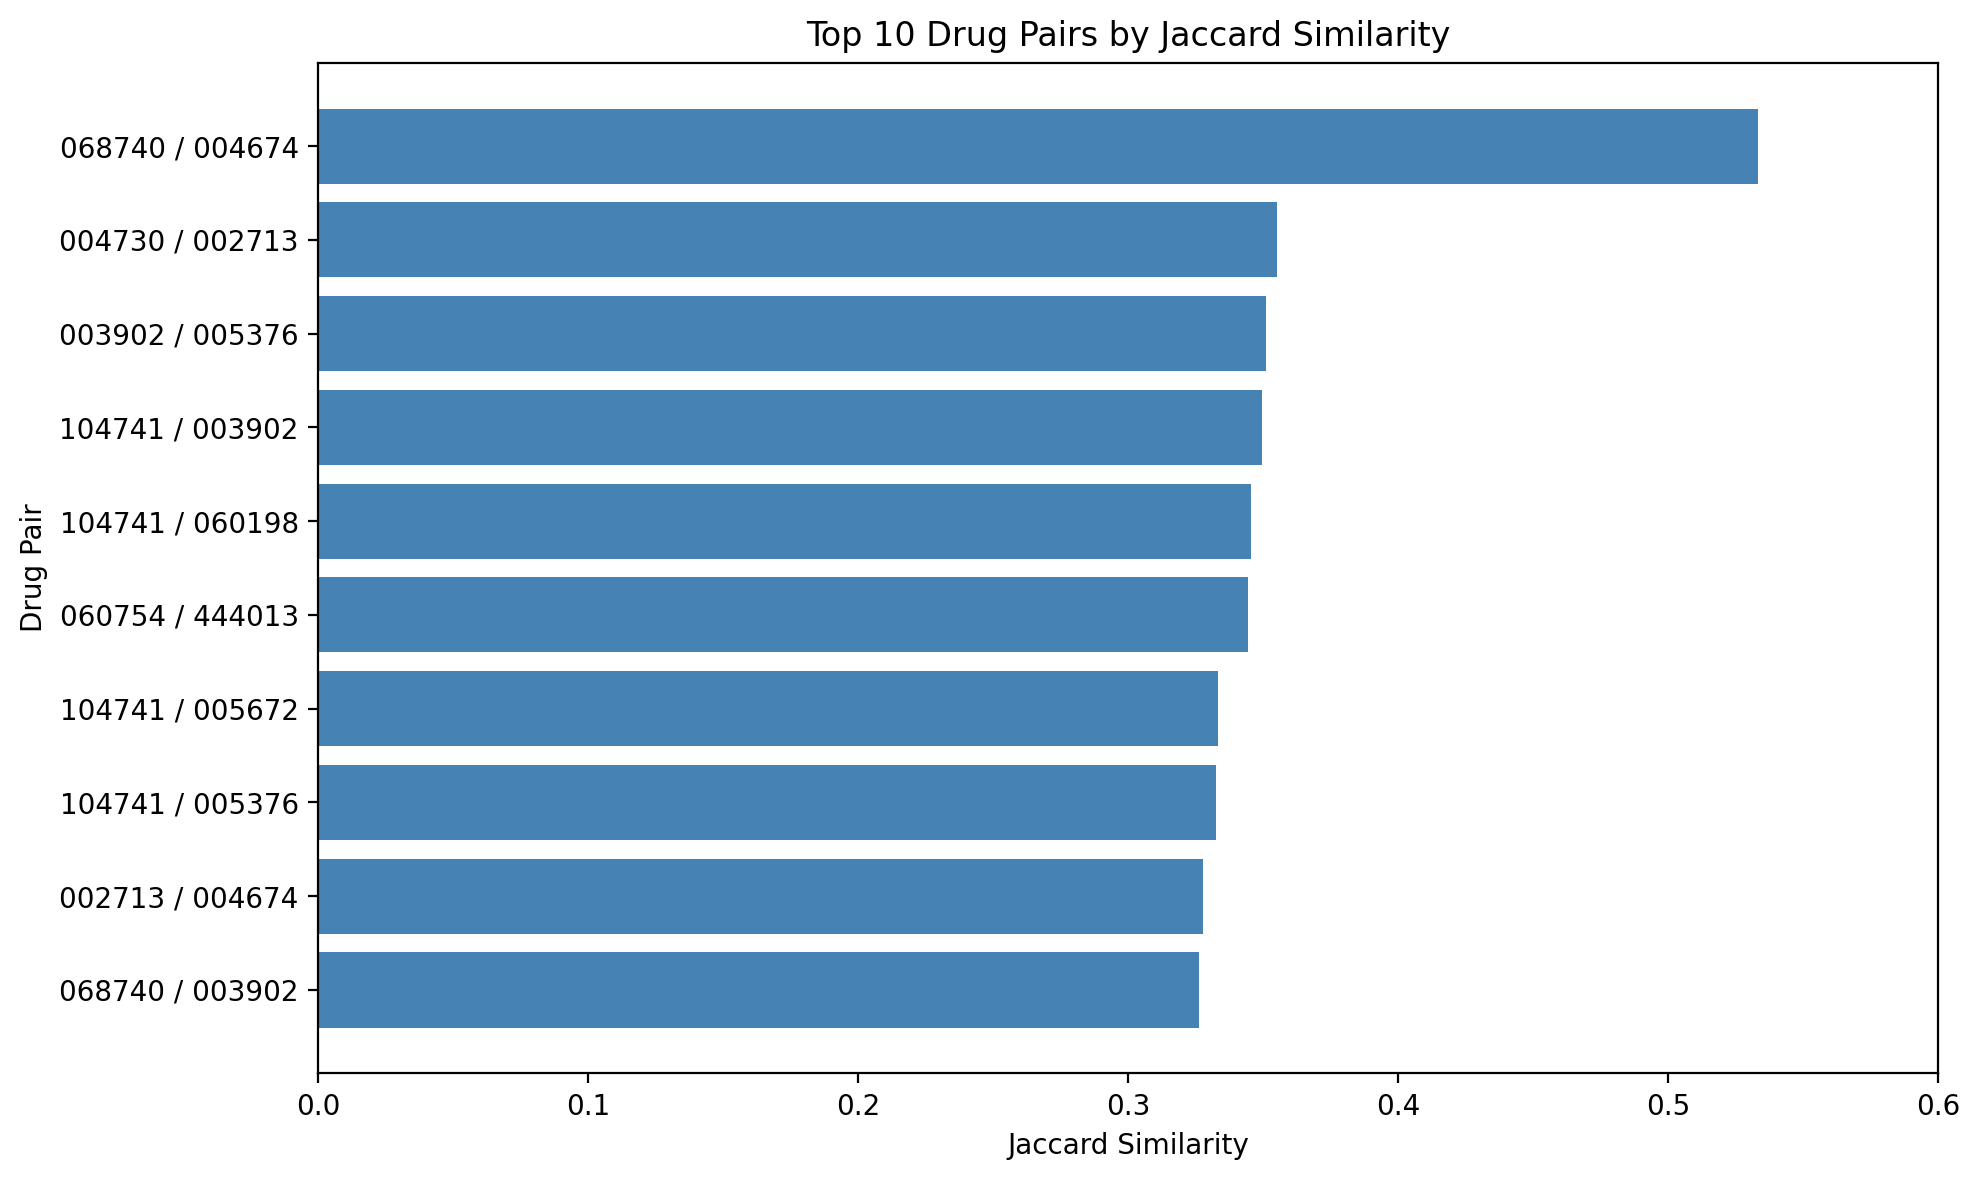

In [15]:

# Create a dataframe from the top 10 pairs
jaccard_df = pd.DataFrame([
    {
        "Drug Pair": f"{u[-6:]} / {v[-6:]}",
        "Jaccard Similarity": d["jaccard"]
    }
    for u, v, d in top_pairs
])

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    jaccard_df["Drug Pair"][::-1],
    jaccard_df["Jaccard Similarity"][::-1],
    color="steelblue"
)

plt.xlabel("Jaccard Similarity")
plt.ylabel("Drug Pair")
plt.title("Top 10 Drug Pairs by Jaccard Similarity")
plt.xlim(0, 0.6)
plt.tight_layout()
plt.show()


**Conclusion**

This project explored drug–side effect relationships using bipartite network analysis and drug–drug network projections. The analysis showed that many drugs share reported side effects, resulting in a highly interconnected network.

By applying different thresholds, I was able to identify smaller connected components with stronger side-effect overlap. Jaccard similarity provided an additional way to compare drug pairs while accounting for differences in their overall side-effect profiles.

Overall, this analysis demonstrates how network methods can help identify patterns in drug–side effect relationships. Future work could explore whether these similarities are associated with shared therapeutic classes or mechanisms of action.